# 4A: Linkage Regions

C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\3464440329.py:131: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result_df = pd.concat([result_df, new_row], ignore_index=True)


SAMD12: Rank 3/11130, Value: 0.9998
ATXN3: Rank 1/8768, Value: 1.0000
RFC1: Rank 1/3778, Value: 1.0000


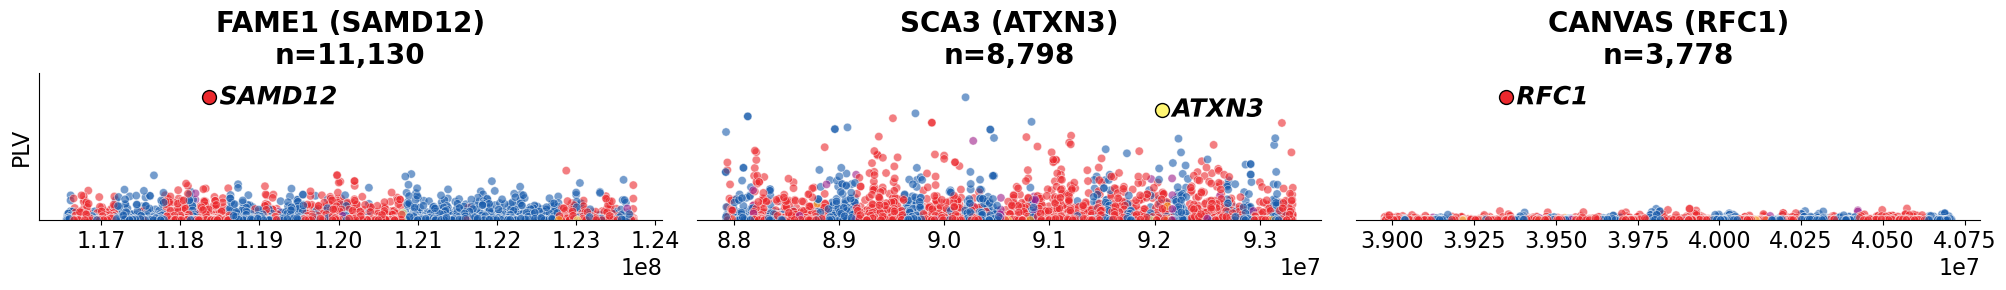

In [1]:
# Linkage region plot of SAMD12, ATXN3, and RFC1
# initial data loading and package import
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib.patheffects as pe

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

df=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz', sep="\t")
# drop to the most common LPS motif per locus
df=df.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

genicAnnotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
df=df.merge(genicAnnotations,how='left',on='TRID')
df.loc[df['region'].isna(),'region']='intergenic'
# function to convert motifs to their simplest rotational form
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]   
    return(min(motifs))

# apply the simplest_motif function the data
df['simpleMotif']=df.loc[:,'LPS_Motif'].apply(simplest_motif)
df['motifLen']=df.loc[:,'simpleMotif'].str.len()
# calculate percentile of standard deviation within each motif grouping
df['percentile_stdev']=df.groupby('motifLen',observed=True)['std'].rank(pct=True)

# drop to just the STRs
df=df.loc[df['motifLen']<=6,:].reset_index(drop=True)

# Define pathogenic TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
df=df.merge(pathogenic.loc[:,['TRID','geneName']],how='left',on='TRID').rename(columns={'geneName':'gene'})
df['Status'] = 'Catalog'
df.loc[~(df['gene'].isna()), 'Status'] = 'Pathogenic'

# Panel definitions (phenotype regions)
regions = [
    'FAME1 chr8_116567651_123732500', 'SCA3 chr14_87921559_93313724', 'CANVAS chr4_38976451_40710564'
]
regionsLabels = [
    'FAME1 (SAMD12)\nn=11,130', 'SCA3 (ATXN3)\nn=8,798', 'CANVAS (RFC1)\nn=3,778'
]

# Category → color mapping
regs = ['intron', 'intergenic', 'UTR_3', 'UTR_5', 'coding']
cols = ['#EB282D', '#195CAC', '#9D1E89', '#F9A31B', '#FFF672']
cm = dict(zip(regs, cols))

# Container for per-panel results (rank/percentile summaries)
result_df = pd.DataFrame(columns=['regionSize','pheno','gene','motif','rank','nTRs','percentile'])

# Plot grid (1 rows × 3 cols = 2 panels)
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(20, 3))
axs = np.atleast_2d(axs)

### Panel loop
for idx, region in enumerate(regions):
    row = idx // 3
    col = idx % 3

    pheno, coords = region.split(' ')
    chrom, start, end = coords.split('_')
    chrom=chrom[3:]
    start = int(start); end = int(end)
    length = end - start
    lab = regionsLabels[idx]

    d = df[df['TRID'].str.startswith(chrom + '-')].copy()
    d[['chr', 'start', 'end','motif']] = d['TRID'].str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
    d['start'] = d['start'].astype(int)
    d['end'] = d['end'].astype(int)
    d = d[(d['start'] > start) & (d['end'] < end)].copy()

    d = d[d['std'].notna()].copy()
    d = d.sample(frac=1, random_state=7)  # shuffle to avoid patterning

    # scatter
    ax = axs[row, col]
    sb.scatterplot(
        x=d['start'], y=d['std'], hue=d['region'], palette=cm,
        ax=ax, marker='o', alpha=0.6, rasterized=True, legend=False
    )

    # Only show y-axis for the leftmost subplot (col == 0)
    if col == 0:
        ax.set_ylabel('PLV', fontsize=16)
        ax.set_yticks([])
    else:
        ax.set_yticks([])
        ax.set_ylabel('')
        ax.spines['left'].set_visible(False)
    
    if len(d) and d['std'].max() > 0:
        ax.set_ylim(0, d['std'].max() * 1.2)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=16)
    ax.xaxis.get_offset_text().set_fontsize(16)
    ax.set_title(lab, fontsize=20, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    total_TRs = len(d)
    if total_TRs:
        d = d.sort_values('percentile_stdev', ascending=True).copy()
        d['Stdev_rank'] = d['percentile_stdev'].rank(ascending=False)

        # annotate pathogenic points and collect ranks
        for _, point in d.iterrows():
            if point.get('Status') == 'Pathogenic':
                percentile_value = 1 - ((point['Stdev_rank'] - 1) / total_TRs)
                new_row = pd.DataFrame({
                    'regionSize': [length],
                    'pheno': [pheno],
                    'gene': [point['gene']],
                    'motif': [point['simpleMotif']],
                    'rank': [int(point['Stdev_rank'])],
                    'nTRs': [total_TRs],
                    'percentile': [percentile_value]
                })
                result_df = pd.concat([result_df, new_row], ignore_index=True)
                print(f"{point['gene']}: Rank {int(point['Stdev_rank'])}/{total_TRs}, Value: {percentile_value:.4f}")

                ax.scatter(point['start'], point['std'],
                           marker='o', color=cm.get(point['region'], 'red'),
                           edgecolors='black', s=100, zorder=3)

                ax.annotate(
                    f"{point['gene']}",
                    (point['start'] + (length * 0.018), point['std']),
                    fontsize=18,
                    path_effects=[pe.withStroke(linewidth=2, foreground='white')],
                    color='black', fontstyle='italic', fontweight='bold',
                    ha='left', va='center'
                )
                
# Layout & export
plt.subplots_adjust(hspace=0.5, wspace=0.4)
plt.tight_layout()
plt.savefig('figures/Figure4A.svg')
plt.savefig('figures/Figure4A.png',dpi=600)

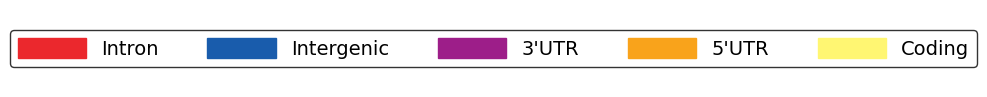

In [2]:
# make the figuure legend
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Provided hex codes
cols = ['#EB282D', '#195CAC', '#9D1E89', '#F9A31B', '#FFF672']

# Labels extracted from the figure
labels = ['Intron', 'Intergenic', "3'UTR", "5'UTR", 'Coding']

# Create a figure and turn off the axes
fig, ax = plt.subplots(figsize=(12, 1))
ax.axis('off')

# Create custom patches for the legend
patches = [mpatches.Patch(color=cols[i], label=labels[i]) for i in range(len(cols))]

# Generate the legend with formatting to match the original style
legend = ax.legend(handles=patches, loc='center', ncol=5, 
                   frameon=True, edgecolor='black', 
                   fontsize=14, handlelength=3.5, handleheight=1.2,
                   columnspacing=2.5)

# Save the figure as an SVG file
plt.savefig('figures/Figure4A_legend.svg', bbox_inches='tight')
plt.savefig('figures/Figure4A_legend.png', dpi=600, bbox_inches='tight')

# 4B: GWAS

C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\418088268.py:81: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d[['chr', 'start', 'end', 'refMotif']] = d.TRID.str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\418088268.py:81: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d[['chr', 'start', 'end', 'refMotif']] = d.TRID.str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\418088268.py:

TCF4: Rank 1/462, Value: 1.0000


C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\418088268.py:81: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d[['chr', 'start', 'end', 'refMotif']] = d.TRID.str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\418088268.py:81: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d[['chr', 'start', 'end', 'refMotif']] = d.TRID.str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\418088268.py:

AFF3: Rank 1/1559, Value: 1.0000


C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\418088268.py:81: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d[['chr', 'start', 'end', 'refMotif']] = d.TRID.str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\418088268.py:81: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d[['chr', 'start', 'end', 'refMotif']] = d.TRID.str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
C:\Users\Matt\AppData\Local\Temp\ipykernel_90980\418088268.py:

FGF14: Rank 1/360, Value: 1.0000


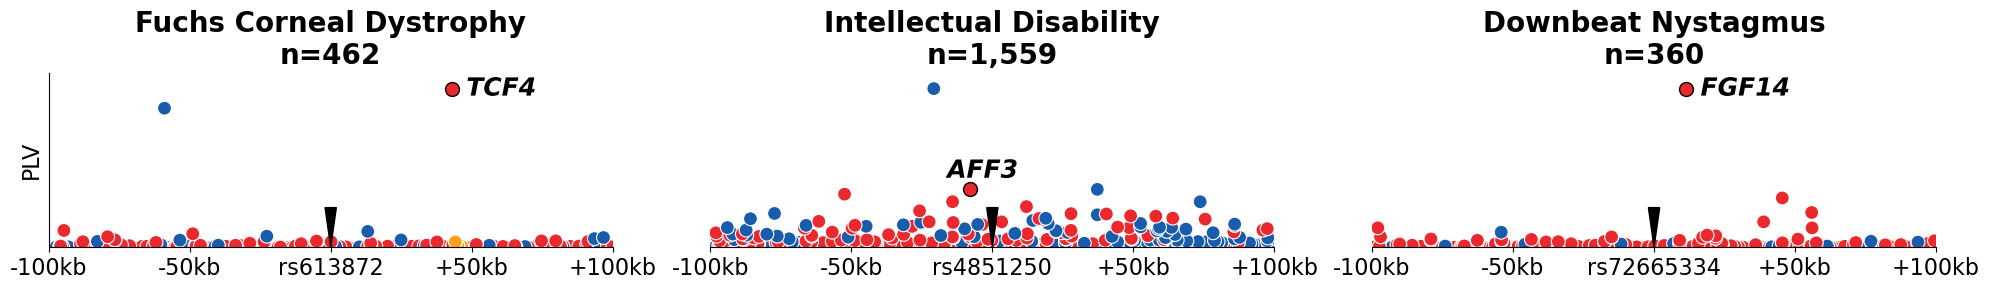

In [8]:
# initial data loading and package import
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib.patheffects as pe

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

#df=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz', sep="\t")
## drop to the most common LPS motif per locus
#df=df.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
#
#genicAnnotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
#df=df.merge(genicAnnotations,how='left',on='TRID')
#df.loc[df['region'].isna(),'region']='intergenic'
## function to convert motifs to their simplest rotational form
#def simplest_motif(motif):
#    i = (motif+motif).find(motif, 1, -1)
#    if i != -1:
#        motif = motif[:i]
#    motifs = []
#    b = len(motif)
#    for i in range(b):
#        c = motif[i:]+motif[:i]
#        motifs.append(c)
#    motifs = [x.upper() for x in motifs]   
#    return(min(motifs))
#
## apply the simplest_motif function the data
#df['simpleMotif']=df.loc[:,'LPS_Motif'].apply(simplest_motif)
#df['motifLen']=df.loc[:,'simpleMotif'].str.len()
## calculate percentile of standard deviation within each motif length grouping
#df['percentile_stdev']=df.groupby('motifLen',observed=True)['std'].rank(pct=True)
## drop to just the STRs
#df=df.loc[df['motifLen']<=6,:].reset_index(drop=True)
#
## Define pathogenic TRIDs
#pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
#df=df.merge(pathogenic.loc[:,['TRID','geneName']],how='left',on='TRID').rename(columns={'geneName':'gene'})
#df['Status'] = 'Catalog'
#df.loc[~(df['gene'].isna()), 'Status'] = 'Pathogenic'

## Manually input gwas snps from literature
data = [
    "chr18\t55543071\trs613872\tFuchs Corneal Dystrophy\nn=462",
    "chr2\t100112831\trs4851250\tIntellectual Disability\nn=1,559",
    "chr13\t102150076\trs72665334\tDownbeat Nystagmus\nn=360"
]
split_data = [item.split('\t') for item in data]

gwas_true_positives=pd.DataFrame(split_data, columns=['Chromosome', 'Position', 'SNP_ID','Trait'])
gwas_true_positives['Position'] = gwas_true_positives['Position'].astype(int)

# Container for per-panel results (rank/percentile summaries)
result_df = pd.DataFrame(columns=['regionSize','pheno','gene','motif','rank','nTRs','percentile'])

# plot the figure
mpl.rcParams['svg.fonttype'] = 'none'
cols = ['#EB282D','#195CAC','#9D1E89','#F9A31B','#FFF672','#64CCF5']
regs = ['intron', 'intergenic', 'UTR_3', 'UTR_5', 'coding']
cm = dict(zip(regs, cols))

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(20, 3))  # 1 row, 3 columns

for index in range(len(gwas_true_positives)):
    
    col = index % 3  # Determine the column index (3 columns)

    chrom = gwas_true_positives.loc[index, 'Chromosome'][3:]
    pos = gwas_true_positives.loc[index, 'Position']
    start1 = pos - 100000
    end1= pos + 100000
    length = end1 - start1
    trait = gwas_true_positives.loc[index,'Trait']
    snp = gwas_true_positives.loc[index, 'SNP_ID']
    
    # Filter data based on region
    d = df[df.TRID.str.contains(chrom + '-')]
    d[['chr', 'start', 'end', 'refMotif']] = d.TRID.str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
    d.start = d.start.astype(int)
    d.end = d.end.astype(int)
    d = d[(d.start > start1) & (d.end < end1)]
    
    d = d.sort_values('std')
    d = d[d['std'].notna()]
    
    sb.scatterplot(x=d['start'], y=d['std'], marker='o', hue=d['region'],s=100, palette=cm, ax=axs[col], rasterized=True)

    # Only show y-axis for the leftmost subplot (col == 0)
    if col == 0:
        axs[col].set_ylabel('PLV', fontsize=16)
        axs[col].set_yticks([])
    else:
        axs[col].set_yticks([])
        axs[col].set_ylabel('')
        axs[col].spines['left'].set_visible(False)

    axs[col].set_ylim(0, max(d['std']) + (max(d['std']) * 0.1))
    axs[col].set_xlim(start1, end1)
    axs[col].legend('', frameon=False)
    axs[col].set_xlabel('')
    axs[col].set_title(trait, size=20, weight='bold')
    axs[col].spines['top'].set_visible(False)
    axs[col].spines['right'].set_visible(False)
    x_value = pos
    
    custom_ticks = [x_value - 100000, x_value - 50000, x_value, x_value + 50000, x_value + 100000]
    custom_tick_labels = ['-100kb','-50kb', snp, '+50kb','+100kb']
    axs[col].set_xticks(custom_ticks)
    axs[col].set_xticklabels(custom_tick_labels, fontsize=16)
    axs[col].fill((x_value, x_value-2000, x_value+2000), (0, max(d['std'])*0.25, max(d['std'])*0.25), color = 'black')

    total_TRs = len(d)
    d['Stdev_rank'] = d['percentile_stdev'].rank(ascending=False)

    
    # Annotate pathogenic points
    for _, point in d.iterrows():
        if point['Status'] == 'Pathogenic':
            percentile_value = 1 - ((point['Stdev_rank'] - 1) / total_TRs)
            print(f"{point['gene']}: Rank {int(point['Stdev_rank'])}/{total_TRs}, Value: {percentile_value:.4f}")
            
            # Create a new DataFrame for the row
            new_row = pd.DataFrame({
                'regionSize': [length],
                'pheno': [trait],
                'gene': [point['gene']],
                'rank': [int(point['Stdev_rank'])],
                'nTRs': [total_TRs],
                'percentile': [percentile_value]
            })

            # Use pd.concat to append the new row to result_df
            result_df = pd.concat([result_df, new_row], ignore_index=True)

            axs[col].scatter(point['start'], point['std'], marker='o', color=cm.get(point['region'], 'red'), edgecolors='black', s=100)
            if point['gene']=='AFF3':
                # placement of AFF3 label above point
                axs[col].annotate(
                    f'{point["gene"]}', 
                    (point['start']-8000, point['std']+4.8), 
                    fontsize=18,
                    path_effects=[pe.withStroke(linewidth=2, foreground="white")],
                    color='black',
                    weight='bold',
                    style='italic',
                    ha='left',  
                    va='center'  
                )
            else:
                # placement of other labels next to points
                axs[col].annotate(
                    f'{point["gene"]}', 
                    (point['start']+5000, point['std']), 
                    fontsize=18,
                    path_effects=[pe.withStroke(linewidth=2, foreground="white")],
                    color='black',
                    weight='bold',
                    style='italic',
                    ha='left',  
                    va='center'  
                )
plt.tight_layout()
plt.savefig('figures/Figure4B.svg')
plt.savefig('figures/Figure4B.png',dpi=600)


# 4C: Prioritization of HTT case without filtering

In [ ]:
%%bash
# HD Case using HiFi data
SAMPLEID="HD_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="4-3074876-3074933-CAG,4-3074927-3074936-CAA,4-3074939-3074966-CCG,4-3074966-3074972-CCT,4-3074983-3074994-GCC,4-3075029-3075040-CCG"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


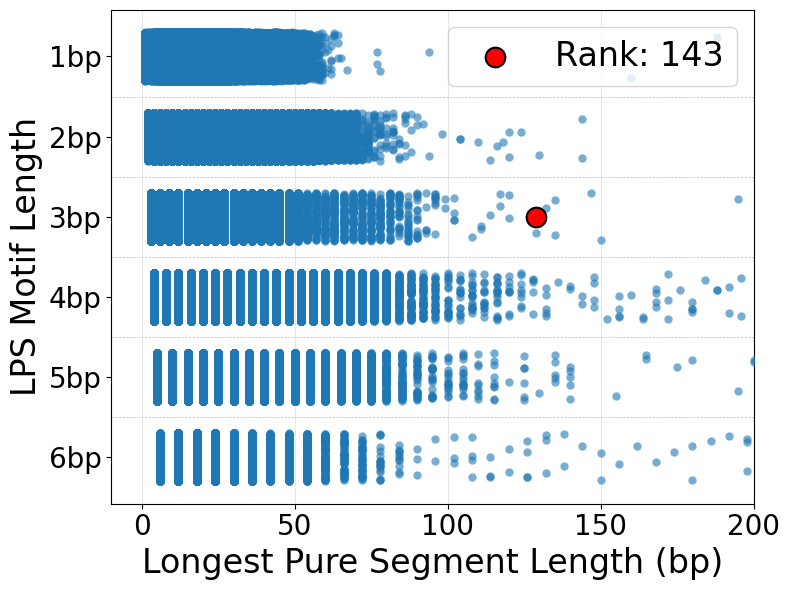

In [ ]:
# No filter plot
import pandas as pd
import matplotlib.pyplot as plt
ranked=pd.read_csv('assets/outlierAnalyses/HTT/noFilt/HD_case_trgt.TR-Explorer_1.0.1_DiscoveryCohort_prioritized_ranks.txt',sep='\t')
pathogenicTRID="4-3074876-3074933-CAG,4-3074927-3074936-CAA,4-3074939-3074966-CCG,4-3074966-3074972-CCT,4-3074983-3074994-GCC,4-3075029-3075040-CCG"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['LPS_Motif_Length']<=6,:].reset_index(drop=True)
ranked=ranked.loc[ranked['LPS_Motif_Length']>=1,:].reset_index(drop=True)
ranked=ranked.loc[ranked['LPS_Length']>0,:].reset_index(drop=True)
ranked['LPS_Motif_Length']=ranked.loc[:,'LPS_Motif_Length'].astype(int)
ranked['Motif_Length_Category'] = ranked['LPS_Motif_Length'].apply(
        lambda x: f"{x}bp" if x <= 6 else "7+bp"
    )

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID].iloc[0,:]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.xlim([-10,200])
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/Figure4C.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/Figure4C.svg", bbox_inches='tight')

# 4D: HTT case with filtering

c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


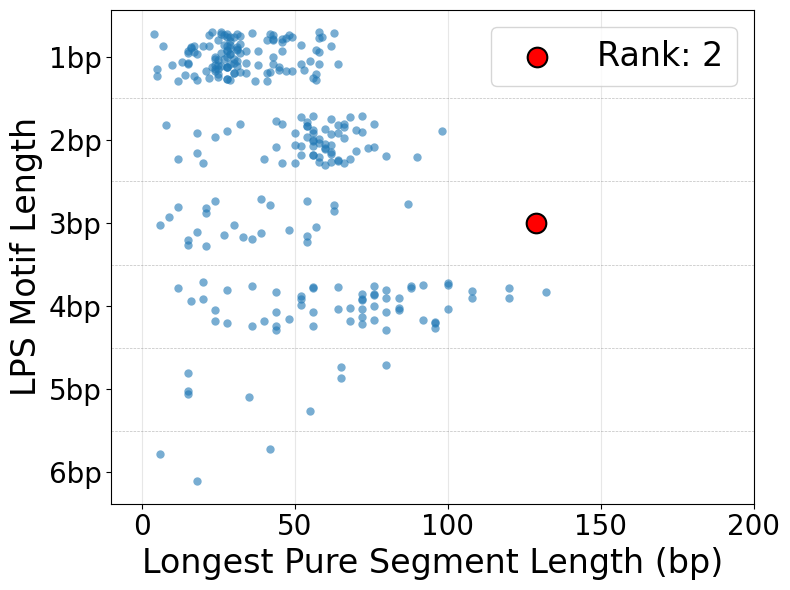

In [ ]:
# Fully filtered plot (bottom)
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/HTT/HD_case_trgt.TR-Explorer_1.0.1_DiscoveryCohort_prioritized_ranks.txt',sep='\t')
pathogenicTRID="4-3074876-3074933-CAG,4-3074927-3074936-CAA,4-3074939-3074966-CCG,4-3074966-3074972-CCT,4-3074983-3074994-GCC,4-3075029-3075040-CCG"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.xlim([-10,200])
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/Figure4D.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/Figure4D.svg", bbox_inches='tight')

# 4E: HPRC Spike-in

In [ ]:
# see hprc_spikeIn_runner.sh for the data processing

In [13]:
# collect output scorecards and produce a figure of the results
import pandas
pathogenicTRs=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
singleShiftTRNames = ['MIR7-2','COMP']
pathogenicTRs = pathogenicTRs.loc[~pathogenicTRs['geneName'].isin(polyAlanineTRNames),:]
pathogenicTRs = pathogenicTRs.loc[~pathogenicTRs['geneName'].isin(singleShiftTRNames),:].reset_index(drop=True)

ranks={}
for sample in ["HG002","HG00438","HG00099","HG00733","HG00741","HG01106","HG01928","HG02055","HG02109","HG03579"]:
    thisSampleResults=pandas.read_csv(f'prioritizeTRWithinSample/HPRC_spikeIn/{sample}_spikeInScores.txt',sep='\t',index_col=0)
    for TRID in thisSampleResults.index.values:
        if TRID in ranks:
            ranks[TRID].append(thisSampleResults.loc[TRID,'noVNTRsRank'])
        else:
            ranks[TRID]=[thisSampleResults.loc[TRID,'noVNTRsRank']]
# separate into coding, intronic, and UTR_5
coding=pathogenicTRs.loc[pathogenicTRs['Region']=='coding',:]
intronic=pathogenicTRs.loc[pathogenicTRs['Region']=='intron',:]
utr=pathogenicTRs.loc[pathogenicTRs['Region'].str.contains('UTR'),:]
ranksCoding=[]
ranksIntronic=[]
ranksUTR=[]
for TRID in coding.TRID.values:
    ranksCoding.extend(ranks[TRID])
for TRID in intronic.TRID.values:
    ranksIntronic.extend(ranks[TRID])
for TRID in utr.TRID.values:
    ranksUTR.extend(ranks[TRID])


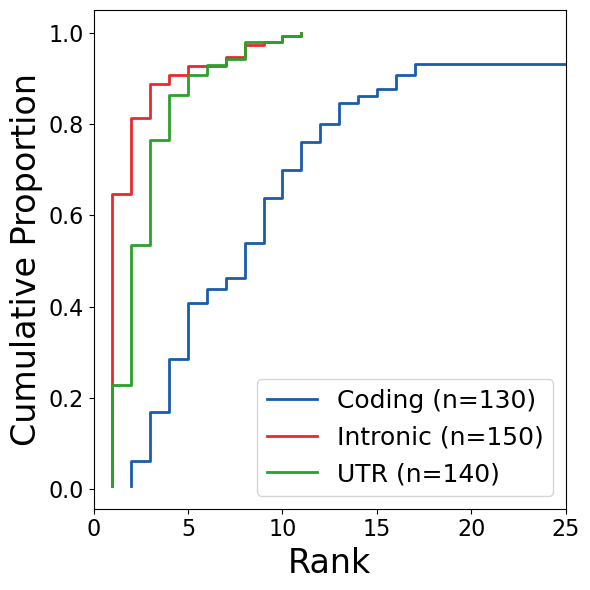

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(6, 6))

categories = {
    'Coding':   (ranksCoding,   '#195CAC'),
    'Intronic': (ranksIntronic, '#EB282D'),
    "UTR":   (ranksUTR,     '#2ca02c'),
}

for label, (ranks, color) in categories.items():
    sorted_ranks = np.sort(ranks)
    ecdf = np.arange(1, len(sorted_ranks) + 1) / len(sorted_ranks)
    ax.step(sorted_ranks, ecdf, label=f'{label} (n={len(ranks)})', color=color, linewidth=2)

#ax.set_xscale('log')
ax.set_xlim([0,25])
ax.set_xlabel('Rank',fontsize=24)
ax.set_ylabel('Cumulative Proportion',fontsize=24)
ax.tick_params(labelsize=16)
#ax.set_title('HPRC spike-in rank distribution')
ax.legend(fontsize=18,title_fontsize=20,loc='lower right')
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(ticker.NullFormatter())
plt.tight_layout()
plt.savefig('figures/Figure4E.png',dpi=600)
plt.savefig('figures/Figure4E.svg')
plt.show()

In [13]:
for label, (ranks, _) in categories.items():
    p50 = np.percentile(ranks, 50)
    print(f"{label}: 50% of ranks are ≤ {p50:.0f}")
    p90 = np.percentile(ranks, 90)
    print(f"{label}: 90% of ranks are ≤ {p90:.0f}")

Coding: 50% of ranks are ≤ 8
Coding: 90% of ranks are ≤ 16
Intronic: 50% of ranks are ≤ 1
Intronic: 90% of ranks are ≤ 4
UTR: 50% of ranks are ≤ 2
UTR: 90% of ranks are ≤ 5
